# Solar Filament Segmentation 2026 — pipeline walkthrough

This notebook walks through every stage of the solution on **one training image**. All logic lives in the modules
under `src/`; the notebook only calls them. Full training (4 encoder families x 5 folds, ~36 h on one RTX 4070),
the ensemble and the gate are run with `bash tools/reproduce_best.sh` (each member is `main.py --config configs/...`).

Steps 6-10 read saved out-of-fold (OOF) artefacts from `outputs/`, which the public repository does not ship;
each such cell checks the path and says what is skipped when it is missing. Only training images and out-of-fold
predictions are used.

## 1. Setup
Put the repository root on `sys.path` and load `configs/base.yaml` with `src.config.load_config` (the resolver
`main.py` uses; experiment yamls are overlays on it). `model.encoder` in `base.yaml` is the best single model; the
four ensemble members (step 5) are yaml overlays that change the encoder. The demo runs on CPU.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd()
while not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.config import load_config

torch.set_num_threads(4)
plt.rcParams.update({"figure.dpi": 72, "image.cmap": "gray", "axes.titlesize": 10})
T0 = time.time()

cfg = load_config(ROOT / "configs/base.yaml")
key = {
    "input": {k: cfg.input[k] for k in ("size", "channels")},
    "target": cfg.target.mode,
    "model": {k: cfg.model[k] for k in ("arch", "encoder")},
    "train": {k: cfg.train[k] for k in ("epochs", "batch_size", "lr", "tile_size", "tiles_per_image", "tile_positive_frac", "region_loss")},
    "infer.tta": cfg.infer.tta,
    "postprocess": {k: cfg.postprocess[k] for k in ("threshold", "min_area", "closing_radius", "merge_radius", "scorer", "tau")},
}
for k, v in key.items():
    print(f"{k:12s} {v}")

input        {'size': 2048, 'channels': ['flat']}
target       soft_mean
model        {'arch': 'Unet', 'encoder': 'tu-efficientnetv2_rw_s'}
train        {'epochs': 30, 'batch_size': 4, 'lr': 0.0003, 'tile_size': 1024, 'tiles_per_image': 4, 'tile_positive_frac': 0.5, 'region_loss': 'dml'}
infer.tta    True
postprocess  {'threshold': 0.5, 'min_area': 300, 'closing_radius': 2, 'merge_radius': 0, 'scorer': 'gbdt', 'tau': 0.2}


## 2. Data
`src.annotations.load_coco` parses the COCO json (its fields are stored as JSON strings) into one row per annotator
record and one row per filament polygon. One image (`stem`) can carry several records, and the metric scores each
record separately. We pick a training image annotated by three annotators.

train: 1154 records / 707 images / 8199 filaments
20141006224634Lh: 3 records -> {'010401-20141006224634Lh': 9, '010402-20141006224634Lh': 9, '010403-20141006224634Lh': 8}


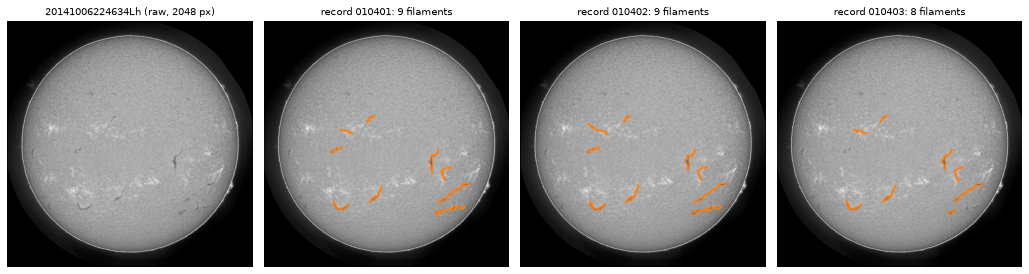

In [2]:
from src.annotations import load_coco
from src.preprocess import read_gray

DATA = ROOT / cfg.data_dir
ANN_JSON = DATA / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
if not ANN_JSON.exists():
    raise FileNotFoundError(f"{ANN_JSON} not found: download the competition data into {DATA} (train/, test/)")

records, annotations = load_coco(ANN_JSON)
STEM = "20141006224634Lh"            # Learmonth, 2014-10-06, 3 annotator records
recs = records[records["stem"] == STEM]
ann = annotations[annotations["stem"] == STEM]
print(f"train: {len(records)} records / {records['stem'].nunique()} images / {len(annotations)} filaments")
print(f"{STEM}: {len(recs)} records ->", ann.groupby("record_id").size().to_dict())
gray = read_gray(DATA / "train" / "train_images" / recs["file_name"].iloc[0])

S = 0.25                              # display scale (2048 -> 512 px)
def small(im):
    return cv2.resize(im.astype(np.float32), None, fx=S, fy=S, interpolation=cv2.INTER_AREA)

fig, axes = plt.subplots(1, len(recs) + 1, figsize=(3.6 * (len(recs) + 1), 3.8))
axes[0].imshow(small(gray)); axes[0].set_title(f"{STEM} (raw, {gray.shape[0]} px)")
for ax, (rid, g) in zip(axes[1:], ann.groupby("record_id")):
    ax.imshow(small(gray))
    for poly in g["polygon"]:
        ax.fill(poly[:, 0] * S, poly[:, 1] * S, fc="none", ec="tab:orange", lw=1)
    ax.set_title(f"record {rid.split('-')[0]}: {len(g)} filaments")
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Pre-processing
`detect_disk` fits the solar limb (Otsu initialisation, then limb-ring points along rays and a robust circle fit that
ignores the grey halo outside the limb). `flatten` divides by the radial median profile, so the quiet Sun is 1.0 at
every radius and filaments are below 1; outside the disk the value is 1. This "flat" channel is the only network input.

disk centre (1023.2, 1023.7), radius 899.7 px


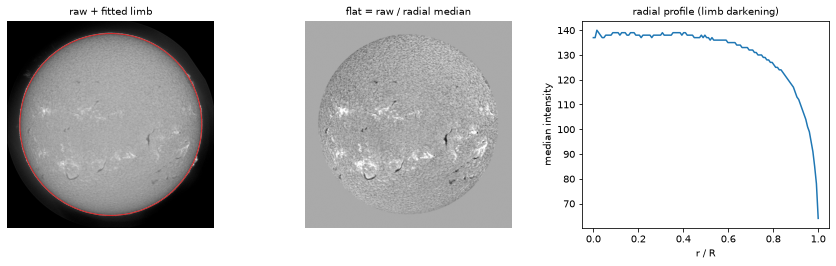

In [3]:
from src.preprocess import detect_disk, flatten, radial_profile

disk = detect_disk(gray)
flat = flatten(gray, disk)
prof = radial_profile(gray, disk)
print(f"disk centre ({disk.cx:.1f}, {disk.cy:.1f}), radius {disk.r:.1f} px")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(small(gray))
axes[0].add_patch(plt.Circle((disk.cx * S, disk.cy * S), disk.r * S, fc="none", ec="tab:red", lw=1))
axes[0].set_title("raw + fitted limb")
axes[1].imshow(small(flat), vmin=0.6, vmax=1.2); axes[1].set_title("flat = raw / radial median")
axes[2].plot(np.linspace(0, 1, len(prof)), prof)
axes[2].set_xlabel("r / R"); axes[2].set_ylabel("median intensity"); axes[2].set_title("radial profile (limb darkening)")
for ax in axes[:2]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Target
The training target is the **mean of the annotators' masks** (`src.data.soft_target`): pixels drawn by all three
annotators are 1, pixels drawn by one of them 1/3. A single record would teach one annotator's style; the consensus
scores best when every record is matched separately.

target values: [0.33 0.67 1.  ]


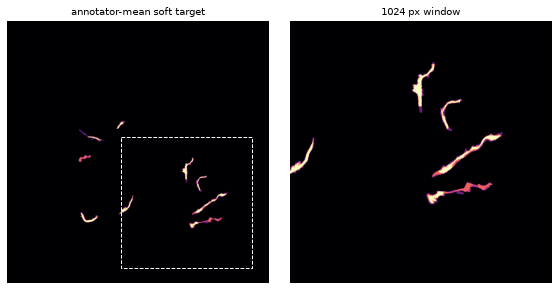

In [4]:
from src.data import soft_target

polys_per_record = [g["polygon"].tolist() for _, g in ann.groupby("record_id")]
target = soft_target(polys_per_record, size=2048).astype(np.float32) / 255.0
print("target values:", np.unique(np.round(target[target > 0], 2)))

ys, xs = np.nonzero(target > 0.5)     # 1024 px window around the filaments, reused below
Y0, X0 = (int(np.clip(np.median(v) - 512, 0, 1024)) for v in (ys, xs))
win = (slice(Y0, Y0 + 1024), slice(X0, X0 + 1024))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(small(target), cmap="magma", vmin=0, vmax=1); axes[0].set_title("annotator-mean soft target")
axes[0].add_patch(plt.Rectangle((X0 * S, Y0 * S), 1024 * S, 1024 * S, fc="none", ec="w", ls="--"))
axes[1].imshow(cv2.resize(target[win], (512, 512), interpolation=cv2.INTER_AREA), cmap="magma", vmin=0, vmax=1)
axes[1].set_title("1024 px window")
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Model and loss
`src.models.build_model` builds a segmentation_models_pytorch U-Net from the `model.*` config keys; the final
ensemble has four encoder families. No weights are downloaded here (`encoder_weights=None`); training starts from
ImageNet weights.

The loss (`src.train.bce_dice_loss`, `region="dml"`) is BCE + the Dice semimetric loss (Wang & Blaschko 2023). On a
soft target, soft Dice rewards saturating p towards 0/1, while DML is minimised at p = target (toy check below).
Training (`src.train.train_fold`, not run here): random 1024 px tiles of the 2048 frame (4 per image per epoch, half
centred on a filament), flips + rot90, 30 epochs, AdamW 3e-4 with warmup + cosine decay, bf16, batch 4.

In [5]:
from src.models import build_model
from src.train import bce_dice_loss

final_cfgs = [p for p in sorted((ROOT / "configs").glob("final_*.yaml")) if not p.stem.startswith("final_ensemble")]
if final_cfgs:
    families = {p.stem: {**dict(load_config(p).model), "encoder_weights": None} for p in final_cfgs}
else:
    print("configs/final_*.yaml not found: using the four final encoder families directly")
    families = {enc: {"arch": "Unet", "encoder": enc, "encoder_weights": None}
                for enc in ("resnext50_32x4d", "efficientnet-b4", "tu-convnext_small", "tu-hrnet_w32")}
for name, mcfg in families.items():
    n = sum(p.numel() for p in build_model(mcfg, in_channels=1).parameters())
    print(f"U-Net + {mcfg['encoder']:20s} {n / 1e6:6.1f} M parameters")

toy_target = torch.full((1, 1, 16, 16), 0.5)          # pixels drawn by half of the annotators
print("\nregion term (loss - BCE) on a target of 0.5 everywhere:")
for label, p in [("p = 0.50 (calibrated)", 0.5), ("p = 0.99 (saturated)", 0.99)]:
    logit = torch.full_like(toy_target, float(np.log(p / (1 - p))))
    bce = bce_dice_loss(logit, toy_target, dice_weight=0.0).item()
    dml = bce_dice_loss(logit, toy_target, region="dml").item() - bce
    dice = bce_dice_loss(logit, toy_target, region="tversky").item() - bce
    print(f"  {label:22s} DML {dml:.3f}   soft Dice {dice:.3f}   (BCE {bce:.3f})")

U-Net + tu-convnext_small      53.6 M parameters
U-Net + efficientnet-b4        20.2 M parameters


U-Net + tu-hrnet_w32           36.0 M parameters


U-Net + resnext50_32x4d        32.0 M parameters

region term (loss - BCE) on a target of 0.5 everywhere:
  p = 0.50 (calibrated)  DML 0.000   soft Dice 0.498   (BCE 0.693)
  p = 0.99 (saturated)   DML 0.328   soft Dice 0.335   (BCE 2.308)


## 6. Prediction
Each family is trained once per fold, and a training image is predicted only by the model of the fold that held it
out (`data/folds.csv`: GroupKFold over 72 h time blocks, since filaments persist for days). Here the held-out
HRNet-W32 model (`exp116`) predicts the 1024 px window with 4-way flip TTA (`src.train._flip_tta`) on CPU. The
pipeline predicts full 2048 frames on GPU and saves every OOF map; the four families' maps are averaged with equal
weights (`tools/average_probs.py`), and that average is used in the next steps.

20141006224634Lh is in validation fold 0


HRNet-W32 fold-0 model: 1024 px window, 4-way flip TTA, 9 s on CPU
4-family averaged OOF map: (2048, 2048)


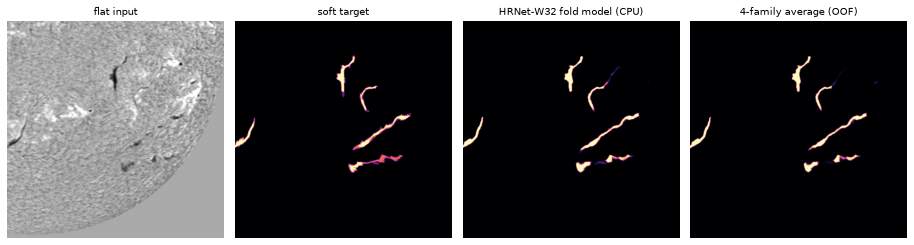

In [6]:
from src.train import _flip_tta

folds = pd.read_csv(ROOT / cfg.folds_csv)
FOLD = int(folds.loc[folds["stem"] == STEM, "fold"].iloc[0])
print(f"{STEM} is in validation fold {FOLD}")

prob_crop = None
w_path = ROOT / f"outputs/exp116-calib/weights/fold{FOLD}.pt"
if w_path.exists():
    model = build_model({"arch": "Unet", "encoder": "tu-hrnet_w32", "encoder_weights": None}, in_channels=1)
    model.load_state_dict(torch.load(w_path, map_location="cpu"))
    model.eval()
    mean, std = cfg.input.norm["flat"]
    x = torch.from_numpy(((flat[win] - mean) / std)[None, None].astype(np.float32))
    t = time.time()
    with torch.no_grad():
        prob_crop = _flip_tta(model, x, False)[0, 0].numpy()
    print(f"HRNet-W32 fold-{FOLD} model: 1024 px window, 4-way flip TTA, {time.time() - t:.0f} s on CPU")
    del model
else:
    print(f"skipped: {w_path.relative_to(ROOT).as_posix()} not found (weights come from training and are not shipped)")

prob = None
ENS = ROOT / f"outputs/ens_dml_rx_b4_cnx43_hr43-full/oof/{STEM}.npy"
if ENS.exists():
    prob = np.load(ENS).astype(np.float32) / 255.0      # saved as uint8 x255 at 2048 px
    print(f"4-family averaged OOF map: {prob.shape}")
elif prob_crop is not None:
    print(f"{ENS.relative_to(ROOT).as_posix()} not found: using the single-model window prediction (0 outside the window)")
    prob = np.zeros((2048, 2048), np.float32)
    prob[win] = prob_crop
else:
    print(f"{ENS.relative_to(ROOT).as_posix()} not found and no weights: steps 7-10 are skipped")

panels = [("flat input", flat[win], dict(vmin=0.6, vmax=1.2)), ("soft target", target[win], dict(cmap="magma", vmin=0, vmax=1))]
if prob_crop is not None:
    panels.append(("HRNet-W32 fold model (CPU)", prob_crop, dict(cmap="magma", vmin=0, vmax=1)))
if prob is not None:
    panels.append(("4-family average (OOF)", prob[win], dict(cmap="magma", vmin=0, vmax=1)))
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.4))
for ax, (title, im, kw) in zip(np.atleast_1d(axes), panels):
    ax.imshow(cv2.resize(im.astype(np.float32), (384, 384), interpolation=cv2.INTER_AREA), **kw)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Instances
`src.postprocess.instances_from_prob` turns the map into instances: threshold 0.5 inside the disk, a closing of
radius 2, connected components and a minimum area of 300 px, with no fragment merging. Annotated filaments
essentially never touch, so connected components are a sound instance definition, and they are pixel-disjoint by
construction.

11 components, areas (px): [688, 931, 971, 1212, 1574, 1646, 1735, 2544, 2778, 3356, 4021]


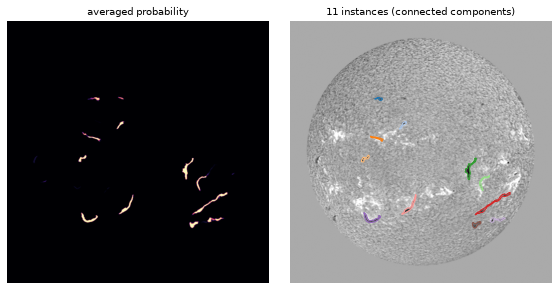

In [7]:
from src.postprocess import instances_from_prob

def outline(ax, mask, color, lw=1.0):
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in contours:
        c = np.vstack([c[:, 0], c[:1, 0]]) * S
        ax.plot(c[:, 0], c[:, 1], color=color, lw=lw)

pp = cfg.postprocess
disk_mask = (disk.radius_map(2048) <= pp.disk_margin).astype(np.uint8)
instances = []
if prob is None:
    print("skipped: no probability map (step 6)")
else:
    instances = instances_from_prob(prob, threshold=pp.threshold, min_area=pp.min_area,
                                    closing_radius=pp.closing_radius, disk_mask=disk_mask, merge_radius=0)
    print(f"{len(instances)} components, areas (px): {sorted(d['area'] for d in instances)}")
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(small(prob), cmap="magma", vmin=0, vmax=1); axes[0].set_title("averaged probability")
    axes[1].imshow(small(flat), vmin=0.6, vmax=1.2)
    for d, c in zip(instances, plt.cm.tab20(np.arange(len(instances)) % 20)):
        outline(axes[1], d["mask"], c)
    axes[1].set_title(f"{len(instances)} instances (connected components)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 8. Expected-IoU gate
Adding a prediction raises the PQ denominator by 0.5 and the numerator by its expected IoU contribution u (mean over
the records of its IoU if IoU > 0.5, else 0), so a prediction helps only when **u > PQ/2**. `src.scorer` regresses u
with LightGBM from 37 test-time features of each component (shape, probability, contrast); the OOF components of
fold k are scored by a model fitted on the other folds (nested). Components with û > τ = 0.20 are kept. The table
lists this image's components from the saved OOF run (`exp118`), next to their true u.

 comp  area  score  elongation  f_contrast_mean     u  u_hat  keep
    0   688  0.831       2.937            0.117 0.000  0.169 False
    1   971  0.956       4.459            0.149 0.730  0.667  True
    2   931  0.916       7.672            0.106 0.198  0.378  True
    3  1212  0.949       3.172            0.132 0.404  0.608  True
    4  3356  0.961       3.117            0.208 0.812  0.803  True
    5  1574  0.920       2.479            0.099 0.677  0.506  True
    6  4021  0.924      15.274            0.114 0.656  0.507  True
    7  2544  0.956       5.520            0.167 0.774  0.676  True
    8  2778  0.962       2.286            0.189 0.794  0.764  True
    9  1646  0.855       4.751            0.135 0.000  0.097 False
   10  1735  0.938       1.967            0.114 0.270  0.525  True

kept 9 / 11; true u of the dropped ones: [0.0, 0.0]


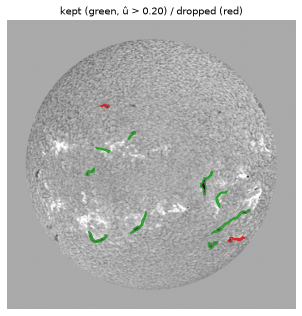

In [8]:
from src.annotations import rle_to_mask

comp = None
SCORER = ROOT / "outputs/exp118-ensemble/scorer_oof.parquet"
if not SCORER.exists():
    print(f"skipped: {SCORER.relative_to(ROOT).as_posix()} not found (written by the ensemble's post-processing run); "
          "without the gate every step-7 component is kept")
else:
    comp = pd.read_parquet(SCORER)
    comp = comp[comp["stem"] == STEM].reset_index(drop=True)
    comp["keep"] = comp["u_hat"] > pp.tau
    print(comp[["comp", "area", "score", "elongation", "f_contrast_mean", "u", "u_hat", "keep"]].round(3).to_string(index=False))
    print(f"\nkept {comp['keep'].sum()} / {len(comp)}; true u of the dropped ones: {comp.loc[~comp['keep'], 'u'].round(2).tolist()}")
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.imshow(small(flat), vmin=0.6, vmax=1.2)
    for r in comp.itertuples():
        outline(ax, rle_to_mask(r.rle), "tab:green" if r.keep else "tab:red", lw=1.2)
    ax.set_title("kept (green, û > 0.20) / dropped (red)"); ax.axis("off")
    plt.tight_layout(); plt.show()

## 9. Metric
`src.metric` reproduces the host's self-evaluation notebook exactly (`tests/test_metric.py`). Every annotator record
is matched separately against the image's predictions (TP: IoU > 0.5), and TP / FP / FN are micro-pooled over all
records. Below: this image against each record and pooled, one annotator scored against the others on the same
image, and the pooled 5-fold OOF result of the final pipeline.

In [9]:
from src.annotations import annotations_to_gt_df
from src.metric import compute_overlaps, panoptic_quality
from src.postprocess import instances_to_rows

gt_df = annotations_to_gt_df(ann)                        # filament_id = '<annotator>-<stem>_<k>'
if comp is not None:
    kept = comp[comp["keep"]].sort_values("u_hat", ascending=False)
    pred_df = pd.DataFrame({"filament_id": [f"{STEM}_{k}" for k in range(1, len(kept) + 1)], "segmentation_rle": kept["rle"].tolist()})
elif instances:
    pred_df = pd.DataFrame(instances_to_rows(STEM, instances))[["filament_id", "segmentation_rle"]]
else:
    pred_df = pd.DataFrame(columns=["filament_id", "segmentation_rle"])

overlaps = compute_overlaps(gt_df, pred_df)
for o in overlaps:
    r = panoptic_quality([o])
    print(f"record {o.record_id.split('-')[0]:>8s}: PQ {r.pq:.3f}  (TP {r.tp}, FP {r.fp}, FN {r.fn})")
res = panoptic_quality(overlaps)
print(f"this image, pooled over {len(overlaps)} records: PQ {res.pq:.3f}  SQ {res.sq:.3f}  RQ {res.rq:.3f}")
print(f"  one-to-many (gt -> #predictions touching it): {dict(sorted(res.one_to_many.items()))}")

pairs = []                                               # each record used as the prediction for the other records
record_of = gt_df["filament_id"].str.rsplit("_", n=1).str[0]
for rid, g in gt_df.groupby(record_of):
    as_pred = g.assign(filament_id=[f"{STEM}_{k}" for k in range(1, len(g) + 1)])
    pairs += compute_overlaps(gt_df[record_of != rid], as_pred)
print(f"annotator vs annotator on this image: PQ {panoptic_quality(pairs).pq:.3f}")

for p in (ROOT / "research/runs/exp118-ensemble/metrics.json", ROOT / "outputs/exp118-ensemble/metrics.json"):
    if p.exists():
        m = json.loads(p.read_text(encoding="utf-8"))["metrics"]
        print(f"\nfinal pipeline, 5-fold OOF on 707 train images ({p.relative_to(ROOT).as_posix()}):")
        print(f"  CV (mean of folds) {m['cv']:.4f} ± {m['cv_std']:.4f}; pooled PQ {m['oof_cv']:.4f} (SQ {m['sq']:.3f}, RQ {m['rq']:.3f})")
        break
else:
    print("\nexp118 metrics.json not found: the final CV is 0.4559 (README)")
print("  human agreement (one annotator vs another, 296 multi-record images): PQ 0.340")

record   010403: PQ 0.624  (TP 7, FP 2, FN 1)
record   010402: PQ 0.581  (TP 7, FP 2, FN 2)
record   010401: PQ 0.601  (TP 8, FP 1, FN 1)
this image, pooled over 3 records: PQ 0.602  SQ 0.725  RQ 0.830
  one-to-many (gt -> #predictions touching it): {1: 26}


annotator vs annotator on this image: PQ 0.539

final pipeline, 5-fold OOF on 707 train images (research/runs/exp118-ensemble/metrics.json):
  CV (mean of folds) 0.4559 ± 0.0039; pooled PQ 0.4554 (SQ 0.686, RQ 0.664)
  human agreement (one annotator vs another, 296 multi-record images): PQ 0.340


## 10. Submission format
Rows are `filament_id = <stem>_<k>` (k in descending score order) with a compressed COCO RLE of the 2048 x 2048 mask.
`src.scorer.rows_from_components` builds them from the kept components, and `src.submission.validate_submission`
checks the columns, the id format, NaN, empty masks, and that masks of one image do not overlap (the host's validator
rejects overlapping masks).

In [10]:
from src.scorer import rows_from_components
from src.submission import COLUMNS, validate_submission

if comp is not None:
    rows = rows_from_components(comp, comp["keep"].values)
else:
    rows = instances_to_rows(STEM, instances)
if not rows:
    print("skipped: no predictions (steps 6-8)")
else:
    sub = pd.DataFrame(rows)[COLUMNS]
    print(validate_submission(sub, expected_stems=[STEM]))
    first = sub.iloc[0]
    print(f"\n{','.join(COLUMNS)}\n{first.filament_id},{first.segmentation_rle[:60]}...  ({len(first.segmentation_rle)} chars)")
print(f"\nnotebook runtime {time.time() - T0:.0f} s")

{'rows': 9, 'images_with_pred': 1, 'images_missing': 0, 'per_image_mean': 9.0, 'area_median': 1735.0}

filament_id,segmentation_rle
20141006224634Lh_1,fTee27go13_OKSQN7ln1LoPN7Po1=01N10001O00100N2O1N2O1N2CkNkQNW...  (286 chars)

notebook runtime 21 s
